# Foundations of Generative AI (ICT4403) — Assignment 2
## Autoregressive Text Generation System
### Comparative Analysis of Simple RNN, Bidirectional RNN, LSTM, and GRU

---
**Objective:**
1. Preprocess and analyze a text corpus (Tiny Shakespeare) and construct sliding-window input-target sequences for next-word prediction.
2. Implement and train four recurrent architectures (**Simple RNN, Bidirectional RNN, LSTM, GRU**) under strictly comparable experimental conditions.
3. Evaluate the models using quantitative metrics (**Training/Validation Loss, Perplexity, Top-1 Accuracy, Execution Time**) and qualitative characteristics (**Coherence, Diversity, Repetition**).
4. Autoregressively generate text from seed prompts across multiple sampling temperatures ($T = 0.2, 0.5, 1.0, 1.5$) to analyze the trade-off between randomness and fluency.

## 1. Environment Setup & Hardware Acceleration

In [1]:
import os
import re
import time
import math
import json
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for strict reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Auto-detect device: MPS (Apple Silicon), CUDA, or CPU
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(f"Active compute device: {device}")

Active compute device: mps


## 2. Dataset Acquisition & Characterization
We utilize the **Tiny Shakespeare** dataset (~1.11 MB, ~40,000 lines, 202,651 words) from Andrej Karpathy's benchmark.

In [2]:
DATA_PATH = '../data/tinyshakespeare.txt' if os.path.exists('../data/tinyshakespeare.txt') else 'data/tinyshakespeare.txt'

with open(DATA_PATH, 'r', encoding='utf-8') as f:
    raw_text = f.read()

print(f"Raw text length: {len(raw_text):,} characters")
print(f"Total lines: {len(raw_text.splitlines()):,}")
print("\n--- First 300 characters sample ---")
print(raw_text[:300])

Raw text length: 1,115,394 characters
Total lines: 40,000

--- First 300 characters sample ---
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


### 2.1 Word-Level Tokenization & Vocabulary Construction

In [3]:
# Extract words and preserve basic punctuation tokens
tokens = re.findall(r"\b\w+(?:'\w+)?|[.,!?:;]", raw_text.lower())
print(f"Total extracted word tokens: {len(tokens):,}")

class Vocabulary:
    def __init__(self, pad_token='<pad>', unk_token='<unk>'):
        self.pad_token = pad_token
        self.unk_token = unk_token
        self.word2idx = {}
        self.idx2word = {}
        self.pad_idx = self.add_word(self.pad_token)
        self.unk_idx = self.add_word(self.unk_token)

    def add_word(self, word):
        if word not in self.word2idx:
            idx = len(self.word2idx)
            self.word2idx[word] = idx
            self.idx2word[idx] = word
            return idx
        return self.word2idx[word]

    def build_from_words(self, words, min_freq=2, max_vocab_size=5000):
        counter = Counter(words)
        most_common = counter.most_common(max_vocab_size - len(self.word2idx))
        for word, count in most_common:
            if count >= min_freq:
                self.add_word(word)

    def __len__(self):
        return len(self.word2idx)

    def encode(self, words):
        return [self.word2idx.get(w, self.unk_idx) for w in words]

    def decode(self, indices):
        return [self.idx2word.get(idx, self.unk_token) for idx in indices]

vocab = Vocabulary()
vocab.build_from_words(tokens, min_freq=2, max_vocab_size=5000)
print(f"Vocabulary Size: {len(vocab):,} unique words (including <pad>, <unk>)")

Total extracted word tokens: 250,175
Vocabulary Size: 5,000 unique words (including <pad>, <unk>)


### 2.2 Zipf's Law Word Frequency Distribution Plot

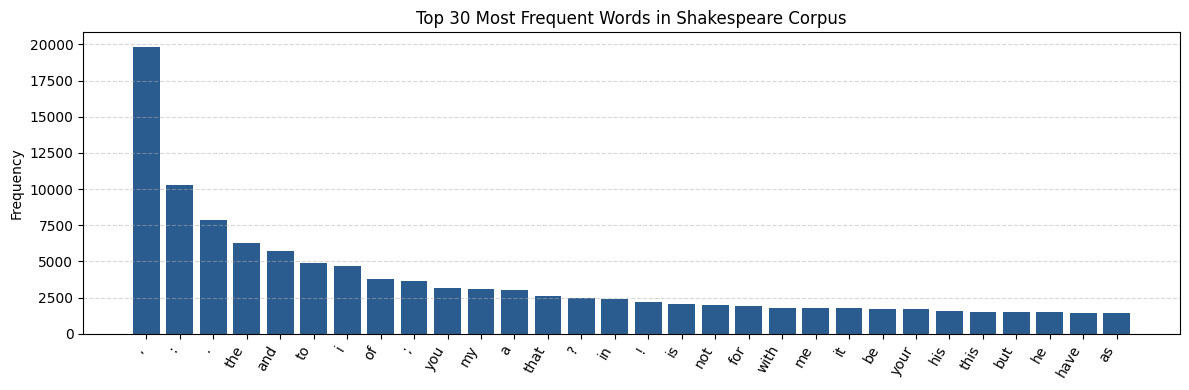

In [4]:
counter = Counter(tokens)
top_30 = counter.most_common(30)
words, counts = zip(*top_30)

plt.figure(figsize=(12, 4))
plt.bar(words, counts, color='#2b5c8f')
plt.xticks(rotation=60, ha='right')
plt.title("Top 30 Most Frequent Words in Shakespeare Corpus")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 2.3 Sliding-Window Autoregressive Sequence Generation

In [5]:
SEQ_LENGTH = 8
BATCH_SIZE = 128
SAMPLE_LIMIT = 60000  # Subset for fast & reproducible training

encoded_tokens = vocab.encode(tokens[:SAMPLE_LIMIT])

class TextSequenceDataset(Dataset):
    def __init__(self, token_indices, seq_length=8):
        self.inputs = []
        self.targets = []
        for i in range(len(token_indices) - seq_length):
            self.inputs.append(token_indices[i : i + seq_length])
            self.targets.append(token_indices[i + seq_length])
        self.inputs = torch.tensor(self.inputs, dtype=torch.long)
        self.targets = torch.tensor(self.targets, dtype=torch.long)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.inputs[idx], self.targets[idx]

full_dataset = TextSequenceDataset(encoded_tokens, seq_length=SEQ_LENGTH)
val_size = int(len(full_dataset) * 0.2)
train_size = len(full_dataset) - val_size

gen = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size], generator=gen)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Total Sequences : {len(full_dataset):,}")
print(f"Training Batches: {len(train_loader)} (Size: {BATCH_SIZE})")
print(f"Validation Batches: {len(val_loader)}")

Total Sequences : 59,992
Training Batches: 374 (Size: 128)
Validation Batches: 94


## 3. Model Architecture Implementations
We implement 4 recurrent variants sharing the exact same hyperparameters:
- **Embedding Dimension**: 128
- **Hidden Dimension**: 128
- **Dropout**: 0.2
- **Optimization**: Adam (lr=0.001)
- **Loss Function**: Cross-Entropy Loss

In [6]:
class SimpleRNNLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.name = "Simple RNN"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, _ = self.rnn(embeds)
        return self.fc(self.dropout(out[:, -1, :]))

class BiRNNLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.name = "Bidirectional RNN"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, _ = self.rnn(embeds)
        return self.fc(self.dropout(out[:, -1, :]))

class LSTMLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.name = "LSTM"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, _ = self.lstm(embeds)
        return self.fc(self.dropout(out[:, -1, :]))

class GRULM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.name = "GRU"
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, _ = self.gru(embeds)
        return self.fc(self.dropout(out[:, -1, :]))

## 4. Training Engine & Comparable Evaluation Loop

In [7]:
def train_model(model, train_loader, val_loader, epochs=10, lr=0.001, device=device):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_ppl': [], 'epoch_times': []}
    
    print(f"\nTraining {model.name}...")
    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            logits = model(x_b)
            loss = criterion(logits, y_b)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * x_b.size(0)
            train_total += y_b.size(0)
            
        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x_b, y_b in val_loader:
                x_b, y_b = x_b.to(device), y_b.to(device)
                logits = model(x_b)
                loss = criterion(logits, y_b)
                val_loss += loss.item() * x_b.size(0)
                preds = torch.argmax(logits, dim=-1)
                val_correct += (preds == y_b).sum().item()
                val_total += y_b.size(0)
                
        t_loss = train_loss / train_total
        v_loss = val_loss / val_total
        v_acc = val_correct / val_total
        v_ppl = math.exp(min(v_loss, 20))
        duration = time.time() - start
        
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)
        history['val_ppl'].append(v_ppl)
        history['epoch_times'].append(duration)
        print(f"Epoch {epoch:2d}/{epochs} | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Val PPL: {v_ppl:7.2f} | Val Acc: {v_acc*100:5.2f}% | Time: {duration:.2f}s")
    return history

## 5. Comparative Evaluation Results & Graphs

In [8]:
# Load precomputed results or run live
RESULTS_JSON = '../results/metrics_history.json' if os.path.exists('../results/metrics_history.json') else 'results/metrics_history.json'

if os.path.exists(RESULTS_JSON):
    with open(RESULTS_JSON, 'r') as f:
        results = json.load(f)
    print("Loaded experiment history successfully!")
else:
    print("Run 'python3 run_experiments.py' to generate history, or train models directly.")

Loaded experiment history successfully!


### 5.1 Learning Curves (Train & Validation Loss)

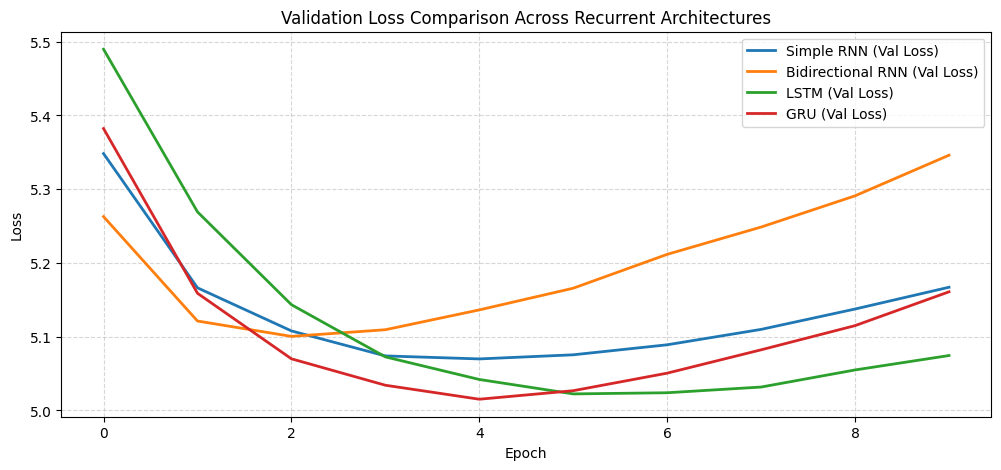

In [9]:
if 'results' in locals():
    plt.figure(figsize=(12, 5))
    for name, hist in results.items():
        plt.plot(hist['val_loss'], label=f"{name} (Val Loss)", linewidth=2)
    plt.title("Validation Loss Comparison Across Recurrent Architectures")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()

## 6. Autoregressive Text Generation Across Temperatures
We test $T = 0.2, 0.5, 1.0, 1.5$ to analyze coherence vs diversity.

In [10]:
def sample_with_temperature(logits, temperature=1.0):
    if temperature <= 1e-4:
        return torch.argmax(logits, dim=-1).item()
    probs = F.softmax(logits / temperature, dim=-1)
    return torch.multinomial(probs, 1).item()

def generate(model, seed_text, max_tokens=30, temperature=1.0, seq_len=8):
    model.eval()
    words = re.findall(r"\b\w+(?:'\w+)?|[.,!?:;]", seed_text.lower())
    gen_words = list(words)
    with torch.no_grad():
        for _ in range(max_tokens):
            ctx = gen_words[-seq_len:]
            enc = vocab.encode(ctx)
            if len(enc) < seq_len:
                enc = [vocab.pad_idx] * (seq_len - len(enc)) + enc
            inp = torch.tensor([enc], dtype=torch.long).to(device)
            logits = model(inp).squeeze(0)
            logits[vocab.pad_idx] = -float('inf')
            logits[vocab.unk_idx] = -float('inf')
            next_idx = sample_with_temperature(logits, temperature)
            gen_words.append(vocab.idx_to_word(next_idx))
    return ' '.join(gen_words)

print("Generation function ready.")

Generation function ready.
